Test pcolormesh function

In [1]:
import cartopy.crs as ccrs
import healpix_geo
import matplotlib.pyplot as plt
import numpy as np
import xarray as xr

from healpix_resample import PSFResampler
from matplotlib.collections import PolyCollection

from swot_healpix.healpix_pcolormesh import healpix_pcolormesh
from swot_healpix.data import SWOT

%matplotlib inline

In [2]:
# Load data

level = 15

track = SWOT(cycle=546, track=19, version="PGC0")

swot_file = track.get_file()
swath = xr.open_dataset(swot_file, group="left", chunks=-1)

swath = swath.isel(num_lines=slice(18_400, 19_100))

# Left swath, we flip to have ascending longitude
swath = swath.isel(num_pixels=slice(None, None, -1))
if track.pass_type == "descending":
    swath = swath.isel(num_lines=slice(None, None, -1))

swath.longitude.load()
swath.latitude.load()
swath.ssh_karin_2.load()

swath = swath.dropna("num_lines", how="all", subset=["longitude"])
swath = swath.dropna("num_pixels", how="all", subset=["longitude"])

# swath = swath.isel(num_lines=slice(0, swath.num_pixels.size))

swath["ssh_karin_2"] -= swath.ssh_karin_2.mean()

ssh_vmin = float(swath.ssh_karin_2.min())
ssh_vmax = float(swath.ssh_karin_2.max())

swath

<xarray.Dataset> Size: 16MB
Dimensions:                                (num_lines: 700, num_pixels: 233)
Coordinates:
    latitude                               (num_lines, num_pixels) float64 1MB ...
    longitude                              (num_lines, num_pixels) float64 1MB ...
Dimensions without coordinates: num_lines, num_pixels
Data variables: (12/16)
    time                                   (num_lines) datetime64[ns] 6kB dask.array<chunksize=(700,), meta=np.ndarray>
    time_tai                               (num_lines) datetime64[ns] 6kB dask.array<chunksize=(700,), meta=np.ndarray>
    latitude_uncert                        (num_lines, num_pixels) float64 1MB dask.array<chunksize=(700, 233), meta=np.ndarray>
    longitude_uncert                       (num_lines, num_pixels) float64 1MB dask.array<chunksize=(700, 233), meta=np.ndarray>
    polarization_karin                     (num_lines) object 6kB dask.array<chunksize=(700,), meta=np.ndarray>
    ssh_karin_2                            (num_lines, num_pixels) float64 1MB ...
    ...                                     ...
    sig0_karin_uncert                      (num_lines, num_pixels) float32 652kB dask.array<chunksize=(700, 233), meta=np.ndarray>
    total_coherence                        (num_lines, num_pixels) float64 1MB dask.array<chunksize=(700, 233), meta=np.ndarray>
    mean_sea_surface_cnescls               (num_lines, num_pixels) float64 1MB dask.array<chunksize=(700, 233), meta=np.ndarray>
    miti_power_250m                        (num_lines, num_pixels) float32 652kB dask.array<chunksize=(700, 233), meta=np.ndarray>
    miti_power_var_250m                    (num_lines, num_pixels) float32 652kB dask.array<chunksize=(700, 233), meta=np.ndarray>
    ancillary_surface_classification_flag  (num_lines, num_pixels) float32 652kB dask.array<chunksize=(700, 233), meta=np.ndarray>
Attributes:
    description:  Unsmoothed SSH measurement data and related information for...

In [3]:
# Resample

lon = swath.longitude.values.ravel()
lat = swath.latitude.values.ravel()
ssh = swath.ssh_karin_2.values.ravel()

resampler = PSFResampler(
    lon_deg=lon,
    lat_deg=lat,
    level=level,
    verbose=True,
)
ssh_hp = resampler.resample(ssh, lam=0.1)
cell_ids = ssh_hp.cell_ids
cell_data = ssh_hp.cell_data

[PSFResampler] area not provided and no shared-latitude-ring structure detected: falling back to a uniform weight of 1.0 per sample.


/home/chaeck/.micromamba/envs/swot-healpix/lib/python3.14/site-packages/healpix_resample/psf.py:346: UserWarning: Sparse invariant checks are implicitly disabled. Memory errors (e.g. SEGFAULT) will occur when operating on a sparse tensor which violates the invariants, but checks incur performance overhead. To silence this warning, explicitly opt in or out. See `torch.sparse.check_sparse_tensor_invariants.__doc__` for guidance.  (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1784990603925/work/aten/src/ATen/Context.cpp:816.)
  M_coo = torch.sparse_coo_tensor(
/home/chaeck/.micromamba/envs/swot-healpix/lib/python3.14/site-packages/healpix_resample/psf.py:570: UserWarning: Sparse CSR tensor support is in beta state. If you miss a functionality in the sparse tensor support, please submit a feature request to https://github.com/pytorch/pytorch/issues. (Triggered internally at /home/conda/feedstock_root/build_artifacts/libtorch_1784990603925/work/aten/src/ATen/S

Itt 0 : 7.007
Itt 4 : 0.002632
Itt 8 : 3.166e-06
Itt 12 : 7.395e-09
Itt 16 : 8.619e-12
Final Itt 20 : 1.062e-14


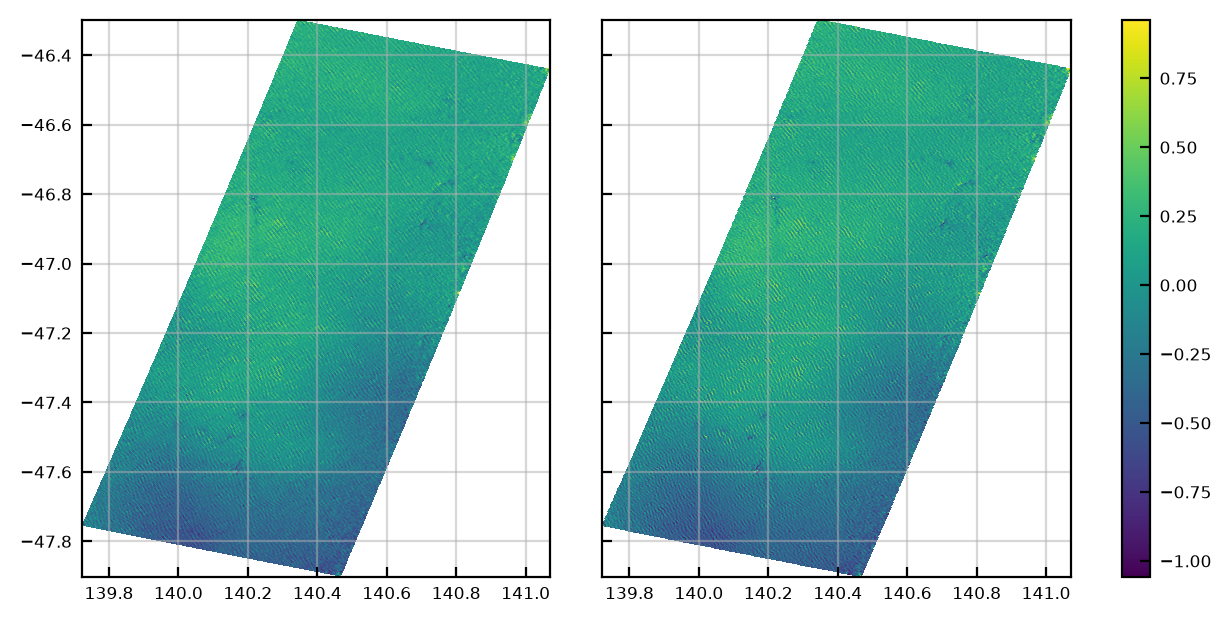

In [4]:
fig, axes = plt.subplots(
    1, 2, figsize=(6, 3), layout="constrained", dpi=200, sharex=True, sharey=True
)
ax1, ax2 = axes

swath.ssh_karin_2.plot.pcolormesh(
    x="longitude",
    y="latitude",
    center=False,
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    add_labels=False,
    add_colorbar=False,
    ax=ax1,
)

ims = healpix_pcolormesh(
    cell_ids,
    cell_data,
    healpix_grid=dict(level=15, indexing_scheme="nested", ellipsoid="WGS84"),
    level_tile=7,
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    ax=ax2,
)
fig.colorbar(ims[0], ax=axes)

for ax in axes:
    ax.set_aspect("equal")
    ax.grid(True)

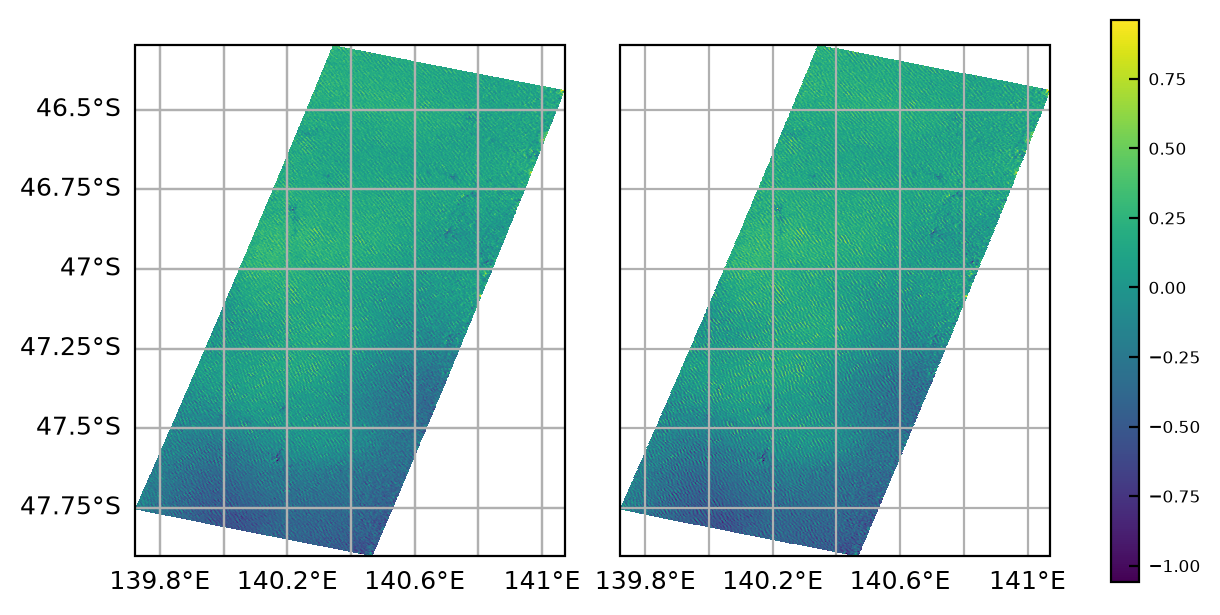

In [5]:
# With cartopy

fig, axes = plt.subplots(
    1,
    2,
    sharex=True,
    sharey=True,
    subplot_kw={"projection": ccrs.PlateCarree()},
    figsize=(6, 3),
    layout="constrained",
    dpi=200,
)
ax1, ax2 = axes

swath.ssh_karin_2.plot.pcolormesh(
    x="longitude",
    y="latitude",
    center=False,
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    add_labels=False,
    add_colorbar=False,
    ax=ax1,
)

ims = healpix_pcolormesh(
    cell_ids,
    cell_data,
    healpix_grid=dict(level=15, indexing_scheme="nested", ellipsoid="WGS84"),
    level_tile=7,
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    ax=ax2,
)
fig.colorbar(ims[0], ax=axes)

for ax in axes:
    ax.set_aspect("equal")
    ax.coastlines()
    ax.gridlines(draw_labels={"bottom": "x"})
ax1.gridlines(draw_labels={"left": "y"})

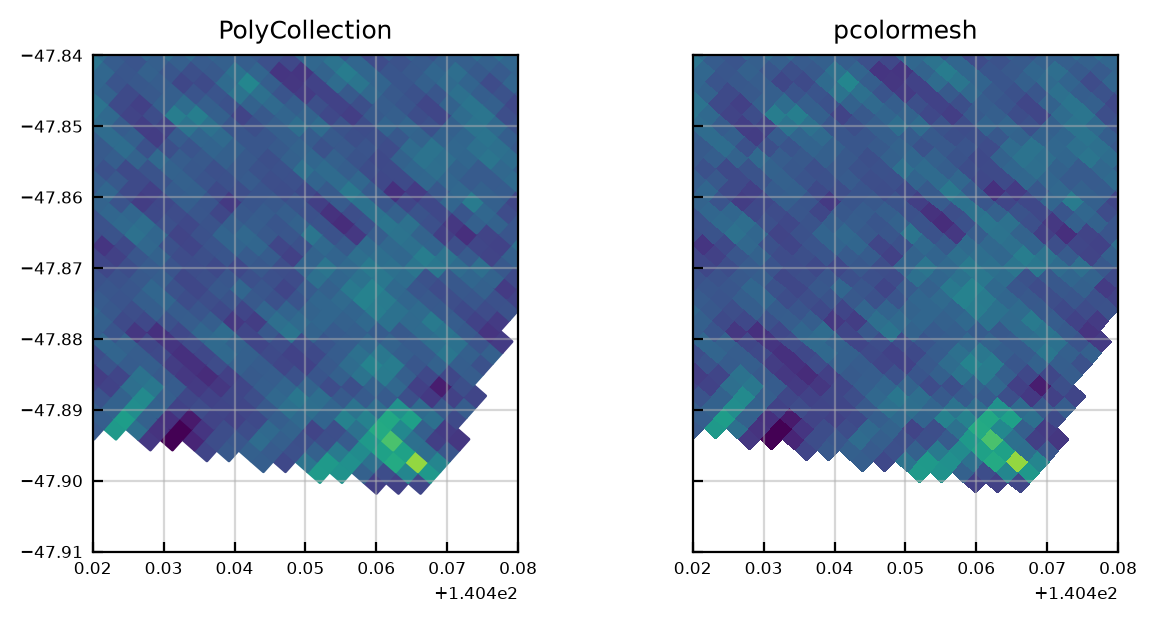

In [6]:
# Zoomed comparison with "slow" method

fig, axes = plt.subplots(
    1,
    2,
    sharex=True,
    sharey=True,
    figsize=(6, 3),
    layout="constrained",
    dpi=200,
)
ax1, ax2 = axes

cell_ids_cut = cell_ids[:16000]
cell_data_cut = cell_data[:16000]

vertices = np.stack(
    healpix_geo.nested.vertices(cell_ids_cut, depth=level, ellipsoid="WGS84"), axis=-1
)
colorizer = plt.Colorizer(norm=plt.Normalize(ssh_vmin, ssh_vmax))
colors = colorizer.to_rgba(cell_data_cut)
polys = PolyCollection(vertices, ec=colors, fc=colors)
ax1.add_collection(polys)
ax1.set_title("PolyCollection")

ims = healpix_pcolormesh(
    cell_ids_cut,
    cell_data_cut,
    healpix_grid=dict(level=15, indexing_scheme="nested", ellipsoid="WGS84"),
    level_tile=7,
    vmin=ssh_vmin,
    vmax=ssh_vmax,
    ax=ax2,
)
ax2.set_title("pcolormesh")

ax1.set_xlim(140.42, 140.48)
ax1.set_ylim(-47.91, -47.84)

for ax in axes:
    ax.set_aspect("equal")